# Do algorithm bans work the same in Llama? — FRLP vs. typicality-ladder predictors

**Artifact `art_-QPYRaFERCBX` (experiment). This is the demo notebook for `method.py`.**

Ask an LLM to *"write a path search"* and it nearly always writes the same algorithm, here BFS. What happens when the prompt **bans** that default (*"do not use BFS"*)? One possibility is that the model moves to an **X-specific substitute**, an algorithm tied to the banned one. The other is that it falls to the next rung of a generic **typicality ladder**.

This artifact replicates the iteration-2 "ban screen" on a second model family, **meta-llama/Llama-3.1-8B-Instruct** (bf16, default chat template, temperature 1.0). It uses two path-search tasks:
- **T1, grid path**, with six catalogue algorithms: BFS, DFS, bidirectional BFS, IDDFS, A* or greedy best-first, and Dijkstra.
- **T2, weighted shortest path.**

**The method: FRLP (forced-ratio latent probability).** How likely is the model to write algorithm *j* under prompt *c*? This matters especially for algorithms that sampling almost never shows. FRLP answers with importance sampling over programs the model wrote **itself** when forced to (*"Implement j"*, with 10 forced paraphrases $F_j$). Those programs are name-scrubbed so that the code does not announce its algorithm:

$$L_j(c) \;=\; \log \frac{1}{M}\sum_{m=1}^{M} \exp\!\big[\,\ell(p_{jm}\mid c) \;-\; \ell(p_{jm}\mid F_j)\,\big]$$

Here $\ell(p\mid c)$ is the log-likelihood of program $p$ after prompt $c$, scored with HF transformers. $\ell(p\mid F_j)$ is the mixture proposal over the forced prompts of $j$.

**What `method.py` does.** It orchestrates 12 stages: setup, vLLM generation, labelling, forced programs, HF scoring, analysis, figures and outputs. Its own code is the final **`outputs`** stage. For every sampled program, that stage predicts the algorithm in four ways:
- **the method:** FRLP top-1 over the non-banned algorithms;
- **baseline 1, the latent ladder:** survivors ranked by their unbanned baseline FRLP;
- **baseline 2, the sampled ladder:** survivors ranked by how often Llama wrote them at baseline;
- **baseline 3, free-form association:** Llama's own answer to *"What is the standard alternative to X?"*

It then scores each prediction against the program's realised mechanism label.

**What this notebook runs.** It runs the CPU-only `outputs` stage on a curated subset bundled in `mini_demo_data.json`. Only the data access is changed. The bundle holds:
- 100 of the 450 sampled T1 programs, with their mechanism labels. All 7 T1 events are represented: baseline, ban BFS, mention BFS, list-all, two-step ban of BFS and DFS, ban DFS, and ban Dijkstra.
- The FRLP instrument's raw measurements: 7,130 log-likelihoods $\ell(p\mid c)$ of the 156 forced T1 programs. They cover the forced proposal prompts and the 35 sampled T1 prompts. **FRLP is recomputed here from them.**
- The result files that `method.py` copies into its output metadata.

vLLM generation and HF scoring (an 8B model on a 24 GB GPU) are not re-run; the bundled data are their outputs.

**Full-run headlines (two tasks, one model; descriptive only).**
- The T1 baseline is *not* collapsed: BFS 77 and DFS 20 out of 100. Banning BFS sends Llama to DFS (63 of 100).
- The FRLP validity gate **fails**. On T1, FRLP implies a BFS share of 0.43 against a sampled share of 0.77.
- Per-sample top-1 accuracy over 743 samples: the empirical sampled ladder reaches **0.70**, against FRLP's 0.59 (paired p < 1e-4). On single bans the two tie (0.67 vs. 0.67).

In [1]:
import subprocess, sys
def _pip(*a): subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *a])

# loguru -- NOT pre-installed on Colab, always install (method.py logs with it)
_pip('loguru==0.7.3')

# numpy, pandas, scipy, matplotlib -- pre-installed on Colab, install locally only (at Colab's versions)
if 'google.colab' not in sys.modules:
    _pip('numpy==2.0.2', 'pandas==2.2.2', 'scipy==1.16.3', 'matplotlib==3.10.0')

In [2]:
# ---- method.py (original import block)
from __future__ import annotations

import argparse
import collections
import json
import subprocess
import sys
import time
from pathlib import Path
from typing import Any

from loguru import logger

# ---- src/analysis_c1.py + src/run_analysis.py (the FRLP code that method.py imports as `A` and `RA`)
import itertools
import math
from dataclasses import dataclass, field

import numpy as np
import pandas as pd
from scipy.stats import rankdata

# ---- notebook additions
import hashlib
from types import SimpleNamespace

import matplotlib.pyplot as plt

In [3]:
GITHUB_DATA_URL = "https://raw.githubusercontent.com/ai-inventor-papers/ai-invention-295f8e-prompt-bans-substitute-not-just-subtract/fork/run_5eGZGmskluur/round-2/experiment-10/demo/mini_demo_data.json"
import http.client
import json
import urllib.request
from pathlib import Path

def load_data():
    try:
        with urllib.request.urlopen(GITHUB_DATA_URL, timeout=15) as response:
            return json.loads(response.read().decode())
    # Network errors, timeouts, a placeholder URL, bad JSON, a cut-off response.
    except (OSError, ValueError, http.client.HTTPException) as e:
        print("GitHub data unavailable, using local mini_demo_data.json:", e)
    local = Path("mini_demo_data.json")
    if local.exists(): return json.loads(local.read_text())
    raise FileNotFoundError("Could not load mini_demo_data.json")

In [4]:
data = load_data()
# The URL is re-published together with this notebook; until then it can still serve an older bundle layout.
if "frlp_scores" not in data and Path("mini_demo_data.json").exists():
    print("the bundle at GITHUB_DATA_URL has an older layout; using local mini_demo_data.json")
    data = json.loads(Path("mini_demo_data.json").read_text())
bundle_meta = data["metadata"]
print(bundle_meta["title"])
print(f"{len(data['examples'])} sampled programs | {bundle_meta['n_forced_programs']} forced programs | "
      f"{bundle_meta['n_score_rows']} FRLP log-likelihoods over {bundle_meta['n_score_conditions']} prompt conditions | "
      f"{len(data['files'])} bundled result files")
print("examples per event:", dict(collections.Counter(f"{r['kind']}:{r['X']}" for r in data["examples"])))
r0 = data["examples"][0]
print(f"\nfirst example {r0['row_id']}: mechanism label {r0['label']!r}, passed hidden tests: {r0['passed']}\n")
print(r0["code"][:700])

the bundle at GITHUB_DATA_URL has an older layout; using local mini_demo_data.json
Do algorithm bans work the same in Llama? -- demo subset
100 sampled programs | 156 forced programs | 7130 FRLP log-likelihoods over 105 prompt conditions | 28 bundled result files
examples per event: {'baseline:None': 22, 'ban:bfs': 22, 'mention:bfs': 11, 'listall:None': 11, 'twostep:bfs+dfs': 12, 'ban:dfs': 11, 'ban:dijkstra': 11}

first example A1|t1|baseline:s0|3: mechanism label 'bfs', passed hidden tests: False

from collections import deque

def solve(grid, start, goal):
    rows, cols = len(grid), len(grid[0])
    directions = [(0, 1), (0, -1), (1, 0), (-1, 0)]  # right, left, down, up

    def is_valid_move(r, c):
        return 0 <= r < rows and 0 <= c < cols and grid[r][c] == '.'

    def reconstruct_path(came_from, current):
        path = []
        while current in came_from:
            path.append(current)
            current = came_from[current]
        path.append(current)
        retur

## Configuration

These are all the tunable parameters of the stage, and the comments give the original values. The bundle holds 100 sampled programs, ordered so that the first 7 cover all 7 T1 events.

The smallest setting, `MAX_EXAMPLES = 7` with `N_BASELINE_SEEDS = 1`, already produces every output. The stage itself takes well under a second on CPU, though, so the values below are the original ones: all 100 bundled programs and all 5 baseline paraphrases. The full run used all 450 sampled programs per task, which the bundle does not contain.

In [5]:
MAX_EXAMPLES = 100         # sampled programs processed (minimal: 7, one per event; bundle: 100 of the 450 T1 programs; full run: 450 per task)
N_BASELINE_SEEDS = 5       # baseline paraphrases s0..s{N-1} averaged by the latent ladder (minimal: 1; original: 5)
FRLP_VARIANT = "full"      # FRLP cell variant used by the predictors (original: "full"; also "body", "gen_proposal", "exp1_5tpl", "correct_only")
SAMPLED_PHASES = ("A1", "A4", "A5", "C")  # generation phases whose programs get predictions (original)
TASKS = ("t1",)            # tasks in the bundle (original: ("t1", "t2"))

## Workspace bridge (`src/ws.py`, `canon/common.py`)

In the repository, `src/ws.py` defines the folders `DATA`, `RESULTS` and `FRLP_DIR`. It also puts exp1's frozen canonical suite (`canon/`) on the path as `C`. `method.py` reads its inputs with `read_jsonl(DATA / ...)` and `load(RESULTS / ...)`.

Here the same paths are **keys into the bundle**, so the original lines of `method.py` read the bundled data unchanged:
- `data/labelled.jsonl` is the demo subset, cut to `MAX_EXAMPLES` rows.
- A file that is not bundled reads as missing (`[]` or `None`), which is also what the original helpers return for a missing file.
- `C` keeps the part of `canon/common.py` this stage uses: the dataset names and the algorithm catalogue, whose order breaks ties in the ladders.

In [6]:
# src/ws.py: the folders -- here only keys into the bundle (nothing is read from or written to disk)
ROOT = Path(".")
DATA = ROOT / "data"
FRLP_DIR = ROOT / "frlp"
RESULTS = ROOT / "results"

# notebook: the bundled files, keyed by their path in the artifact; data/labelled.jsonl is the demo subset
FILES = dict(data["files"])
FILES["data/labelled.jsonl"] = data["examples"][:MAX_EXAMPLES]


def _bundled(p: Path) -> Any:
    return FILES.get(Path(p).as_posix())


def read_jsonl(p: Path) -> list[dict[str, Any]]:
    """src/ws.py -> canon read_jsonl: the rows of a .jsonl file ([] when absent)."""
    return list(_bundled(p) or [])


def load(p: Path) -> Any:
    """method.py: a results JSON file (None when absent)."""
    v = _bundled(p)
    return json.loads(v) if isinstance(v, str) else v


def setup_logging(name: str) -> None:
    logger.remove()
    logger.add(sys.stdout, level="INFO", format="{time:HH:mm:ss}|{level:<7}|{message}")
    # (src/ws.py also adds a rotating DEBUG file sink, logs/{name}.log)


# canon/common.py: exp1's frozen protocol constants -- the part this stage uses
TASK_DATASET_NAME = {"t1": "T1_grid_path", "t2": "T2_weighted_shortest_path"}
CATALOGUE: dict[str, dict[str, str]] = {
    "t1": {
        "bfs": "breadth-first search (BFS)",
        "dfs": "depth-first search (DFS)",
        "bibfs": "bidirectional BFS",
        "iddfs": "iterative deepening DFS (IDDFS)",
        "astar_gbfs": "A* or greedy best-first search",
        "dijkstra": "Dijkstra's algorithm",
    },
    "t2": {
        "dijkstra": "Dijkstra's algorithm",
        "bf_spfa": "Bellman-Ford or SPFA",
        "bidijkstra": "bidirectional Dijkstra",
        "floyd": "Floyd-Warshall",
        "dial": "Dial's bucket-queue algorithm",
    },
}
C = SimpleNamespace(
    TASK_DATASET_NAME=TASK_DATASET_NAME,
    CATALOGUE=CATALOGUE,
    MODES={t: list(CATALOGUE[t].keys()) for t in CATALOGUE},  # catalogue order = tie-break order of the ladders
    sha256_file=lambda p: hashlib.sha256(_bundled(p).encode("utf-8")).hexdigest(),  # hashes the bundled raw file
)
print(f"{len(FILES)} bundled files; data/labelled.jsonl -> {len(read_jsonl(DATA / 'labelled.jsonl'))} rows")

29 bundled files; data/labelled.jsonl -> 100 rows


## The FRLP estimator, part 1: score matrix and proposal (`src/analysis_c1.py`, verbatim)

`TaskData` holds one task's measurements. `lf[p, c]` is the log-likelihood $\ell(p\mid c)$ of forced program $p$ (rows) after prompt condition $c$ (columns), summed over the program's tokens. `lb` holds the same scores restricted to the code body.

Condition names encode the prompt:

| condition | prompt |
|---|---|
| `baseline:s0` | a plain task paraphrase |
| `ban:bfs:w3` | ban template W3, naming BFS |
| `mention:bfs:w3` | the mention twin: names BFS without banning it |
| `listall:p0` | lists all catalogue algorithms |
| `twostep:bfs+dfs:w1` | bans both BFS and DFS |
| `forced:dfs:k4` | forced paraphrase k4 for DFS (*"Implement DFS"*) |

`proposal` gives each program its log proposal density, $\log q(p) = \log \mathrm{mean}_k \exp \ell(p\mid \mathrm{forced}_{j,k})$. This is the mixture over all forced prompts used for its algorithm $j$, i.e. the distribution the program was actually sampled from.

In [7]:
TEMPLATES = (1, 2, 3, 4, 5)
HALVES = (1, 2)
ESS_FLOOR = 5.0


@dataclass
class TaskData:
    task: str
    algs: list[str]  # FRLP-measured algorithms (catalogue order)
    d: str
    s_star: str
    prog: pd.DataFrame  # program_id, j, half, passed, generating_cond (row order of the matrices)
    conds: list[str]
    lf: np.ndarray  # [P, C] l_full (NaN = not scored)
    lb: np.ndarray  # [P, C] l_body
    cidx: dict[str, int] = field(default_factory=dict)
    jidx: np.ndarray | None = None  # [P] algorithm index
    hidx: np.ndarray | None = None  # [P] half index 0/1

    def __post_init__(self):
        self.cidx = {c: i for i, c in enumerate(self.conds)}
        self.jidx = np.array([self.algs.index(j) for j in self.prog["j"]])
        self.hidx = np.array([int(h) - 1 for h in self.prog["half"]])

    def has(self, c: str) -> bool:
        return c in self.cidx


def logmeanexp(a: np.ndarray, axis: int = -1) -> np.ndarray:
    m = np.nanmax(a, axis=axis, keepdims=True)
    m = np.where(np.isfinite(m), m, 0.0)
    with np.errstate(invalid="ignore"):
        e = np.exp(a - m)
    e = np.where(np.isnan(a), 0.0, e)
    n = np.sum(~np.isnan(a), axis=axis, keepdims=True)
    with np.errstate(divide="ignore", invalid="ignore"):
        out = m + np.log(np.sum(e, axis=axis, keepdims=True) / n)
    return np.where(n > 0, out, np.nan).squeeze(axis)


def proposal(td: TaskData, variant: str = "full") -> np.ndarray:
    """log q(p) = l(p | F_j): mixture over every forced prompt used for j (full / body), the generating paraphrase
    ('gen_proposal'), or exp1's 5 standard templates ('exp1_5tpl')."""
    mat = td.lb if variant == "body" else td.lf
    out = np.full(len(td.prog), np.nan)
    pcols = [i for c, i in td.cidx.items() if c.startswith("forced:") or c.startswith("forced_desc:")]
    for r, (j, gen) in enumerate(zip(td.prog["j"], td.prog["generating_cond"])):
        if variant == "gen_proposal":
            out[r] = mat[r, td.cidx[gen]]
            continue
        if variant == "exp1_5tpl":
            cols = [td.cidx[f"forced:{j}:k{k}"] for k in range(5) if f"forced:{j}:k{k}" in td.cidx]
        else:
            cols = [i for i in pcols if td.conds[i].split(":")[1] == j]
        v = mat[r, cols]
        out[r] = logmeanexp(v[~np.isnan(v)]) if np.any(~np.isnan(v)) else np.nan
    return out

## Part 2: importance-weighted FRLP cells and their ESS (`src/analysis_c1.py`, verbatim)

`importance` forms the log importance ratios $D[p, c] = \ell(p\mid c) - \log q(p)$. `make_cells` then averages $\exp D$ over each algorithm's programs. It works in log space with a max-shift, once over all programs and once per half; the halves are two disjoint parts of the forced set, used for split-half statistics.

The result is the FRLP cell $L_j(c)$ together with its effective sample size, $\mathrm{ESS} = (\sum w)^2 / \sum w^2$. A low ESS means a single program dominates the estimate. In the full run the median cell ESS was only 2.5, which is one reason the FRLP gate failed.

In [8]:
@dataclass
class Cells:
    Lh: np.ndarray  # [J, 2, C]
    La: np.ndarray  # [J, C]
    ESSh: np.ndarray  # [J, 2, C]
    ESSa: np.ndarray  # [J, C]
    Nh: np.ndarray  # [J, 2] programs per half (with multiplicity)


def make_cells(td: TaskData, D: np.ndarray, counts: np.ndarray | None = None, mask: np.ndarray | None = None) -> Cells:
    """D [P, C] = log importance ratios; counts [P] bootstrap multiplicities; mask [P] program subset."""
    P, C = D.shape
    J = len(td.algs)
    w = np.ones(P) if counts is None else counts.astype(float)
    if mask is not None:
        w = w * mask
    Lh = np.full((J, 2, C), np.nan)
    ESSh = np.full((J, 2, C), np.nan)
    La = np.full((J, C), np.nan)
    ESSa = np.full((J, C), np.nan)
    Nh = np.zeros((J, 2))
    for j in range(J):
        sel_j = td.jidx == j
        Dj = D[sel_j]
        wj = w[sel_j]
        hj = td.hidx[sel_j]
        valid = ~np.isnan(Dj)
        with np.errstate(all="ignore"):
            import warnings
            with warnings.catch_warnings():
                warnings.simplefilter("ignore", RuntimeWarning)
                M = np.nanmax(np.where(valid & (wj[:, None] > 0), Dj, np.nan), axis=0) if np.any(wj > 0) else np.full(C, np.nan)
        M = np.where(np.isfinite(M), M, 0.0)
        E = np.where(valid, np.exp(np.where(valid, Dj, 0.0) - M), 0.0)
        for h in (0, 1):
            sh = (hj == h)
            ww = (wj * sh)[:, None] * valid
            s1 = np.sum(ww * E, axis=0)
            s2 = np.sum(ww * E ** 2, axis=0)
            n = np.sum(ww, axis=0)
            Nh[j, h] = float(np.sum(wj * sh))
            with np.errstate(divide="ignore", invalid="ignore"):
                Lh[j, h] = np.where((n > 0) & (s1 > 0), M + np.log(s1 / n), np.nan)
                ESSh[j, h] = np.where(s2 > 0, s1 ** 2 / s2, np.nan)
        ww = wj[:, None] * valid
        s1 = np.sum(ww * E, axis=0)
        s2 = np.sum(ww * E ** 2, axis=0)
        n = np.sum(ww, axis=0)
        with np.errstate(divide="ignore", invalid="ignore"):
            La[j] = np.where((n > 0) & (s1 > 0), M + np.log(s1 / n), np.nan)
            ESSa[j] = np.where(s2 > 0, s1 ** 2 / s2, np.nan)
    return Cells(Lh=Lh, La=La, ESSh=ESSh, ESSa=ESSa, Nh=Nh)


def importance(td: TaskData, variant: str = "full") -> np.ndarray:
    base = td.lb if variant == "body" else td.lf
    lq = proposal(td, variant if variant in ("body", "gen_proposal", "exp1_5tpl") else "full")
    return base - lq[:, None]

## Part 3: the `View` accessor and helpers (`src/analysis_c1.py`, verbatim)

`View.a(cond, algs)` returns the FRLP vector $L_j(\text{cond})$ over a list of algorithms, and it is the only accessor the `outputs` stage needs. The class's other methods compute ban gains (`G`), the mention prime (`prime`) and the generic ladder profile (`u`). They serve the C1 share analysis in `src/run_analysis.py`, which is not re-run here.

`jsonable` converts numpy values for the JSON output. The last line makes both modules available under the names `method.py` imports them by, `A` and (in the next section) `RA`.

In [9]:
def centre(v: np.ndarray) -> np.ndarray:
    return v - np.mean(v)


def unit(v: np.ndarray) -> np.ndarray:
    n = np.linalg.norm(v)
    return v / n if n > 0 else v * np.nan


class View:
    """Accessors over one Cells object with a template draw `tw` (list of 5 template ids)."""

    def __init__(self, td: TaskData, cells: Cells, tw: list[int] | None = None):
        self.td, self.c = td, cells
        self.tw = list(tw) if tw is not None else list(TEMPLATES)
        self.ai = {a: i for i, a in enumerate(td.algs)}

    def h(self, cond: str, h: int, algs: list[str]) -> np.ndarray:
        if cond not in self.td.cidx:
            return np.full(len(algs), np.nan)
        ci = self.td.cidx[cond]
        return np.array([self.c.Lh[self.ai[a], h - 1, ci] for a in algs])

    def a(self, cond: str, algs: list[str]) -> np.ndarray:
        if cond not in self.td.cidx:
            return np.full(len(algs), np.nan)
        ci = self.td.cidx[cond]
        return np.array([self.c.La[self.ai[a], ci] for a in algs])

    def ess_h(self, cond: str, h: int, algs: list[str]) -> np.ndarray:
        if cond not in self.td.cidx:
            return np.full(len(algs), np.nan)
        ci = self.td.cidx[cond]
        return np.array([self.c.ESSh[self.ai[a], h - 1, ci] for a in algs])

    # ---- gains
    def G(self, X: str, w: int, h: int, algs: list[str], ref: str = "neutral") -> np.ndarray:
        ban = self.h(f"ban:{X}:w{w}", h, algs)
        if ref == "neutral":
            return ban - self.h(f"neutral:{X}:w{w}:h{h}", h, algs)
        return ban - self.h(f"mention:{X}:w{w}", h, algs)  # veto row (mention reference)

    def prime(self, X: str, w: int, h: int, algs: list[str]) -> np.ndarray:
        return self.h(f"mention:{X}:w{w}", h, algs) - self.h(f"neutral:{X}:w{w}:h{h}", h, algs)

    # ---- generic profiles over all algorithms
    def generic(self, half: int | None = None) -> dict[str, np.ndarray]:
        algs = self.td.algs
        out: dict[str, np.ndarray] = {}
        hs = HALVES if half is None else (half,)
        out["nonce"] = np.nanmean([self.h(f"nonce:w{w}", h, algs) - self.h(f"nonce_neutral:w{w}:h{h}", h, algs)
                                   for w in self.tw for h in hs], axis=0)
        get = (lambda c: self.a(c, algs)) if half is None else (lambda c: self.h(c, half, algs))
        for k in range(1, 7):
            if self.td.has(f"edit:k{k}"):
                out[f"edit{k}"] = get(f"edit:k{k}") - get("baseline_empty")
        out["novelty"] = get("novelty") - np.nanmean([get(f"baseline:s{s}") for s in range(5)], axis=0)
        return out

    def u(self, half: int | None = None, raw_mean: bool = False) -> np.ndarray:
        g = self.generic(half)
        edits = [g[k] for k in g if k.startswith("edit")]
        if raw_mean:
            return np.mean([g["nonce"]] + edits + [g["novelty"]], axis=0)
        types = [g["nonce"], np.mean(edits, axis=0) if edits else np.full(len(self.td.algs), np.nan), g["novelty"]]
        types = [unit(centre(t)) for t in types if not np.any(np.isnan(t))]
        if not types:  # degenerate bootstrap draw (a half with no programs): undefined profile
            return np.full(len(self.td.algs), np.nan)
        return np.mean(types, axis=0)


def jsonable(o: Any) -> Any:
    if isinstance(o, dict):
        return {str(k): jsonable(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)):
        return [jsonable(v) for v in o]
    if isinstance(o, np.ndarray):
        return [jsonable(v) for v in o.tolist()]
    if isinstance(o, (np.floating, float)):
        return None if (isinstance(o, float) or isinstance(o, np.floating)) and not np.isfinite(o) else float(o)
    if isinstance(o, (np.integer,)):
        return int(o)
    if isinstance(o, (np.bool_,)):
        return bool(o)
    return o


# notebook: method.py imports src/analysis_c1.py as `A`
A = SimpleNamespace(TEMPLATES=TEMPLATES, HALVES=HALVES, ESS_FLOOR=ESS_FLOOR, TaskData=TaskData, logmeanexp=logmeanexp,
                    proposal=proposal, Cells=Cells, make_cells=make_cells, importance=importance, centre=centre,
                    unit=unit, View=View, jsonable=jsonable)

## Loading a task (`src/run_analysis.py`)

`load_task` builds a `TaskData` from two inputs:
- **the forced set:** the self-written, name-scrubbed programs. An algorithm with fewer than 10 usable programs is excluded; on T2 that removed bidirectional Dijkstra and Dial.
- **the score table.** The one change from the original is its source: a single bundled long table instead of the per-condition parquet parts `frlp/parts/<task>/*.parquet`, with the same columns.

`variant_cells` is verbatim.

`association` returns the free-form association counts, i.e. how often Llama answered *j* to *"What is the standard alternative to X?"*. The run saved exactly this aggregate of `data/free_answers.jsonl` in `results/c1.json`, and the notebook reads it from there.

In [10]:
VARIANTS = ("full", "body", "gen_proposal", "exp1_5tpl", "correct_only")


def load_task(task: str) -> A.TaskData:
    sel = load(RESULTS / "selections.json")  # notebook: bundled (original: json.loads((RESULTS / ...).read_text()))
    summ = load(RESULTS / "forced_set_summary.json")["per_algorithm"]
    fs = [r for r in read_jsonl(DATA / "forced_set.jsonl") if r["task"] == task and r["scrub_mode"] != "dropped"
          and not summ[f"{task}:{r['j']}"]["excluded_M_lt_10"]]
    order = list(C.MODES[task])
    algs = [j for j in order if any(r["j"] == j for r in fs)]
    fs.sort(key=lambda r: (algs.index(r["j"]), r["half"], r["program_id"]))
    prog = pd.DataFrame([{"program_id": r["program_id"], "j": r["j"], "half": r["half"], "passed": r["passed"],
                          "generating_cond": r["generating_cond"], "n_tokens": r["n_tokens"]} for r in fs])
    # notebook: the parquet parts frlp/parts/<task>/*.parquet are bundled as one long table (same columns)
    sc = data["frlp_scores"][task]
    df = pd.DataFrame(sc["rows"], columns=sc["columns"])[["program_id", "cond", "l_full", "l_body", "n_tokens"]]
    df = df[df["program_id"].isin(set(prog["program_id"]))]
    conds = sorted(df["cond"].unique())
    pf = df.pivot_table(index="program_id", columns="cond", values="l_full", aggfunc="first")
    pb = df.pivot_table(index="program_id", columns="cond", values="l_body", aggfunc="first")
    pf = pf.reindex(index=prog["program_id"], columns=conds)
    pb = pb.reindex(index=prog["program_id"], columns=conds)
    sub = sel[f"{task}_substitute"]["s_star"] if f"{task}_substitute" in sel else None
    return A.TaskData(task=task, algs=algs, d=sel[f"{task}_default"], s_star=sub, prog=prog, conds=conds,
                      lf=pf.to_numpy(dtype=float), lb=pb.to_numpy(dtype=float))


def disputed_rows() -> set[str]:
    p = RESULTS / "llama_label_audit.json"
    return set((load(p) or {}).get("disputed_row_ids", []))  # notebook: bundled


def variant_cells(td: A.TaskData, variant: str, counts: np.ndarray | None = None) -> A.Cells:
    base = variant if variant not in ("correct_only", "audit_disputed_removed") else "full"
    D = A.importance(td, base)
    mask = None
    if variant == "correct_only":
        mask = td.prog["passed"].to_numpy(dtype=float)
    elif variant == "audit_disputed_removed":  # plan S1: audit agreement < 0.9 -> C1 without the disputed forced programs
        bad = disputed_rows()
        mask = np.array([0.0 if pid.split("|", 2)[2] in bad else 1.0 for pid in td.prog["program_id"]])
    return A.make_cells(td, D, counts=counts, mask=mask)


def association(sel: dict[str, Any]) -> dict[str, dict[str, dict[str, int]]]:
    # notebook: data/free_answers.jsonl is not bundled; the run saved this exact aggregate in results/c1.json
    out = {task: load(RESULTS / "c1.json")["association_counts"][task] for task in TASKS}
    _ = sel
    return out


# notebook: method.py imports src/run_analysis.py as `RA`
RA = SimpleNamespace(TASKS=TASKS, VARIANTS=VARIANTS, load_task=load_task, variant_cells=variant_cells,
                     association=association)

### A first look: FRLP at baseline vs. what Llama actually wrote

Before running the stage, here is the estimator applied to the plain baseline prompts (`baseline:s0` … `baseline:s{N_BASELINE_SEEDS-1}`). For each algorithm the table gives:
- its FRLP $L_j$ in nats;
- its ESS;
- its FRLP-implied share, $\exp L_j / \sum_k \exp L_k$, averaged over the prompts;
- how often Llama actually wrote it.

This is the FRLP gate's calibration check (a). The full run found that FRLP implies a BFS share of about 0.43 and puts DFS on top, while Llama wrote BFS 77% of the time. Each forced program is name-scrubbed and scored as a continuation of every prompt, so a mis-calibrated cell usually comes from a few programs with a large importance weight (low ESS).

In [11]:
td = RA.load_task("t1")
v = A.View(td, RA.variant_cells(td, FRLP_VARIANT))
print(f"t1: algorithms={td.algs} | forced programs={len(td.prog)} | prompt conditions={len(td.conds)} | "
      f"default d={td.d} | sampled substitute s*={td.s_star}")
print("forced programs per algorithm (M):", td.prog["j"].value_counts().reindex(td.algs).to_dict())

base_conds = [f"baseline:s{s}" for s in range(N_BASELINE_SEEDS)]
L = np.array([v.a(c, td.algs) for c in base_conds])                                 # [prompts, J] FRLP in nats
ess = np.array([[v.c.ESSa[v.ai[j], td.cidx[c]] for j in td.algs] for c in base_conds])
implied = np.mean(np.exp(L) / np.nansum(np.exp(L), axis=1, keepdims=True), axis=0)  # as in the FRLP gate's check (a)
base_rows = [r for r in read_jsonl(DATA / "labelled.jsonl") if r["task"] == "t1" and r["kind"] == "baseline"]
cnt = collections.Counter(r["label"] for r in base_rows)
full_cnt = load(RESULTS / "collapse.json")["t1"]["attempted_counts"]
n_full = sum(full_cnt.values())
peek = pd.DataFrame({"FRLP L_j (nats)": L.mean(axis=0), "median ESS": np.median(ess, axis=0),
                     "FRLP-implied share": implied,
                     f"sampled share, demo (n={len(base_rows)})": [cnt.get(j, 0) / max(1, len(base_rows)) for j in td.algs],
                     f"sampled share, full run (n={n_full})": [full_cnt.get(j, 0) / n_full for j in td.algs]},
                    index=td.algs)
print(f"\nbaseline prompts {base_conds}:")
print(peek.round(3).to_string())
print(f"(labels outside the catalogue: demo 'other' {cnt.get('other', 0)}, full run 'other' {full_cnt.get('other', 0)})")

t1: algorithms=['bfs', 'dfs', 'bibfs', 'iddfs', 'astar_gbfs', 'dijkstra'] | forced programs=156 | prompt conditions=105 | default d=bfs | sampled substitute s*=dfs
forced programs per algorithm (M): {'bfs': 30, 'dfs': 28, 'bibfs': 11, 'iddfs': 28, 'astar_gbfs': 30, 'dijkstra': 29}

baseline prompts ['baseline:s0', 'baseline:s1', 'baseline:s2', 'baseline:s3', 'baseline:s4']:
            FRLP L_j (nats)  median ESS  FRLP-implied share  sampled share, demo (n=22)  sampled share, full run (n=100)
bfs                  -0.857      13.514               0.433                       0.773                             0.77
dfs                  -0.589       5.574               0.566                       0.182                             0.20
bibfs               -16.989       2.169               0.000                       0.000                             0.00
iddfs               -13.467       1.410               0.000                       0.000                             0.00
astar_gbfs        

## `method.py`: the `outputs` stage

The next cells are `method.py`'s own code, one function per cell. The only edits are marked `# notebook:`:
- nothing is written to disk, and the result is returned instead;
- two hard-coded values became config parameters: the sampled phases and the number of baseline paraphrases.

`samples_jsonl` projects the labelled program rows onto the shared per-sample schema (`data/samples.jsonl`). Each row carries the prompt condition and the realised **mechanism label**. The label comes from exp1's canonical labeller, which runs runtime tracing and AST rules and calls an LLM judge only when those two disagree. It re-checked at 22/22 reference programs.

In [12]:
# ------------------------------------------------------------------------------------------------ outputs
def samples_jsonl() -> list[dict[str, Any]]:
    keys = ("task", "condition", "kind", "X", "template", "paraphrase_id", "sample_id", "seed", "model", "decoding",
            "label", "labeller_source", "passed", "code_sha256", "code", "text", "n_gen_tokens", "finish_reason",
            "extract_method", "runtime_label", "ast_label", "judge_label", "phase", "row_id", "prompt_sha")
    rows = [{k: r.get(k) for k in keys} for r in read_jsonl(DATA / "labelled.jsonl")]
    # C.write_jsonl(DATA / "samples.jsonl", rows)  # notebook: kept in memory, not written
    return rows

### The method and the three baselines

`predictions` returns four predictors. Each maps (task, prompt, banned set) to one algorithm among the **survivors**, i.e. the measured algorithms that are not banned.

| predictor | role | rule |
|---|---|---|
| `frlp_top1` | **method** | argmax of the FRLP $L_j(c)$ under **this sample's own prompt** $c$ |
| `ladder` | baseline 1 | argmax of the mean *baseline* FRLP, a latent typicality ladder that ignores the prompt |
| `sampled_ladder` | baseline 2 | argmax of the sampled baseline frequency, an empirical ladder (ties go by catalogue order) |
| `association` | baseline 3 | Llama's modal free-form answer to *"What is the standard alternative to X?"*; the latent ladder if there is no X |

`banned_for` reads the banned set off the row: one algorithm for a ban, two for a two-step ban, none otherwise. A *mention* names X without banning it.

In [13]:
def predictions(tds: dict[str, Any], views: dict[str, Any], sel: dict[str, Any], assoc: dict[str, Any]):
    import numpy as np

    def frlp_top1(task: str, cond: str, banned: list[str]) -> str:
        v = views[task]
        Se = [j for j in v.td.algs if j not in banned]
        L = v.a(cond, Se)
        return Se[int(np.nanargmax(L))] if Se and not np.all(np.isnan(L)) else "none"

    def ladder(task: str, banned: list[str]) -> str:
        v = views[task]
        Se = [j for j in v.td.algs if j not in banned]
        L = np.nanmean([v.a(f"baseline:s{s}", Se) for s in range(N_BASELINE_SEEDS)], axis=0)  # notebook: range(5)
        return Se[int(np.nanargmax(L))] if Se else "none"

    base_counts = {t: collections.Counter(r["label"] for r in read_jsonl(DATA / "labelled.jsonl")
                                          if r["task"] == t and r["kind"] == "baseline") for t in views}

    def sampled_ladder(task: str, banned: list[str]) -> str:
        """Empirical typicality ladder: sampled baseline frequency renormalised over the survivors (catalogue order on ties)."""
        Se = [j for j in views[task].td.algs if j not in banned]
        return max(Se, key=lambda j: (base_counts[task].get(j, 0), -Se.index(j))) if Se else "none"

    def association(task: str, X: str | None, banned: list[str]) -> str:
        if X is None:
            return ladder(task, banned)
        cnt = assoc[task].get(X, {})
        Se = [j for j in views[task].td.algs if j not in banned]
        best = max(Se, key=lambda j: (cnt.get(j, 0), -Se.index(j))) if Se else "none"
        return best if cnt.get(best, 0) > 0 else ladder(task, banned)

    return frlp_top1, ladder, association, sampled_ladder


def banned_for(r: dict[str, Any], sel: dict[str, Any]) -> list[str]:
    if r["kind"] == "ban":
        return [r["X"]]
    if r["kind"] == "twostep":
        return r["X"].split("+")
    return []

### `outputs()`: predict every sampled program, score the predictors, assemble `method_out.json`

The stage takes every sampled program from phases A1 (baseline), A4 (ban, mention, list-all), A5 (two-step) and C (non-default bans). For each one it does the following:
1. It computes the four predictions.
2. It decides whether the sample is **scorable**: code was extracted and the label is not banned.
3. For scorable samples, it records top-1 accuracy, i.e. whether the prediction equals the mechanism label. Accuracy is accumulated per event `task|kind|X`, over all events, and over single bans.

The stage also emits two more datasets, the forced programs and the free-form answers. Both come out empty here, because the bundle holds only the sampled T1 programs.

In [14]:
def outputs() -> dict[str, Any]:
    import numpy as np

    # notebook: `from src import analysis_c1 as A` / `from src import run_analysis as RA` -> the namespaces A, RA above

    rows = samples_jsonl()
    sel = load(RESULTS / "selections.json")  # notebook: bundled (original: json.loads((RESULTS / ...).read_text()))
    tds = {t: RA.load_task(t) for t in RA.TASKS}
    views = {t: A.View(td, RA.variant_cells(td, FRLP_VARIANT)) for t, td in tds.items()}  # notebook: "full" -> FRLP_VARIANT
    assoc = RA.association(sel)
    frlp_top1, ladder, association, sampled_ladder = predictions(tds, views, sel, assoc)
    datasets = []
    acc = collections.defaultdict(lambda: collections.Counter())
    for task in RA.TASKS:
        ex = []
        for r in rows:
            if r["task"] != task or r["phase"] not in SAMPLED_PHASES:  # notebook: ("A1", "A4", "A5", "C")
                continue
            banned = banned_for(r, sel)
            X = r["X"] if r["kind"] in ("ban",) else (sel[f"{task}_default"] if r["kind"] == "twostep" else None)
            p_frlp = frlp_top1(task, r["condition"], banned)
            p_lad = ladder(task, banned)
            p_ass = association(task, X, banned)
            p_smp = sampled_ladder(task, banned)
            lab = r["label"]
            scorable = lab not in ("no_code",) and lab not in banned
            if scorable:
                ev = f"{task}|{r['kind']}|{r['X']}"
                acc[ev]["n"] += 1
                acc[ev]["frlp"] += int(p_frlp == lab)
                acc[ev]["ladder"] += int(p_lad == lab)
                acc[ev]["association"] += int(p_ass == lab)
                acc[ev]["sampled_ladder"] += int(p_smp == lab)
            ex.append({"input": f"task={task} | condition={r['condition']} | prompt_sha256={r['prompt_sha']}",
                       "output": str(lab),
                       "predict_frlp_top1": p_frlp, "predict_latent_ladder": p_lad, "predict_sampled_ladder": p_smp,
                       "predict_association": p_ass,
                       "metadata_task": task, "metadata_kind": r["kind"], "metadata_banned": banned,
                       "metadata_template": r["template"], "metadata_paraphrase_id": r["paraphrase_id"],
                       "metadata_sample_id": r["sample_id"], "metadata_seed": r["seed"], "metadata_passed": r["passed"],
                       "metadata_labeller_source": r["labeller_source"], "metadata_code_sha256": r["code_sha256"],
                       "metadata_phase": r["phase"], "metadata_row_id": r["row_id"], "metadata_scorable": scorable,
                       "metadata_n_gen_tokens": r["n_gen_tokens"], "metadata_finish_reason": r["finish_reason"]})
        datasets.append({"dataset": f"{C.TASK_DATASET_NAME[task]}__llama31_sampled", "examples": ex})
    # forced programs (FRLP proposal set) and free-form association answers
    fs = {r["row_id"]: r for r in read_jsonl(DATA / "forced_set.jsonl")}
    fex = []
    for r in rows:
        if r["phase"] not in ("A2", "A6"):
            continue
        f = fs.get(r["row_id"])
        fex.append({"input": f"task={r['task']} | condition={r['condition']} | prompt_sha256={r['prompt_sha']}",
                    "output": str(r["label"]), "predict_intended_algorithm": str(r["X"]),
                    "metadata_task": r["task"], "metadata_in_frlp_set": f is not None,
                    "metadata_half": f["half"] if f else None, "metadata_scrub_mode": f["scrub_mode"] if f else None,
                    "metadata_passed": r["passed"], "metadata_labeller_source": r["labeller_source"],
                    "metadata_code_sha256": r["code_sha256"], "metadata_row_id": r["row_id"]})
    datasets.append({"dataset": "forced_programs__llama31", "examples": fex})
    fr = read_jsonl(DATA / "free_answers.jsonl")  # notebook: not bundled -> []
    ext = (load(RESULTS / "sensitivities.json") or {}).get("freeform_vs_exp1_openrouter_llama", {})
    datasets.append({"dataset": "freeform_association__llama31", "examples": [
        {"input": f"task={r['task']} | free-form 'standard alternative to {r['X']}'", "output": r["label"],
         "predict_exp1_openrouter_llama_top1": str((ext.get(r["task"], {}).get(r["X"], {}) or {}).get("exp1_openrouter_top1")),
         "metadata_task": r["task"], "metadata_X": r["X"], "metadata_raw_answer": r["text"],
         "metadata_sample_id": r["sample_id"], "metadata_seed": r["seed"]} for r in fr]})
    pred_summary = {ev: {"n": c["n"], "acc_frlp_top1": c["frlp"] / max(1, c["n"]), "acc_latent_ladder": c["ladder"] / max(1, c["n"]),
                         "acc_sampled_ladder": c["sampled_ladder"] / max(1, c["n"]),
                         "acc_association": c["association"] / max(1, c["n"])} for ev, c in sorted(acc.items())}
    tot = collections.Counter()
    for c in acc.values():
        tot.update(c)
    pred_summary["ALL"] = {"n": tot["n"], "acc_frlp_top1": tot["frlp"] / max(1, tot["n"]),
                           "acc_latent_ladder": tot["ladder"] / max(1, tot["n"]),
                           "acc_sampled_ladder": tot["sampled_ladder"] / max(1, tot["n"]),
                           "acc_association": tot["association"] / max(1, tot["n"])}
    bans = [c for ev, c in acc.items() if "|ban|" in ev]
    bt = collections.Counter()
    for c in bans:
        bt.update(c)
    pred_summary["SINGLE_BANS"] = {"n": bt["n"], "acc_frlp_top1": bt["frlp"] / max(1, bt["n"]),
                                   "acc_latent_ladder": bt["ladder"] / max(1, bt["n"]),
                                   "acc_sampled_ladder": bt["sampled_ladder"] / max(1, bt["n"]),
                                   "acc_association": bt["association"] / max(1, bt["n"])}
    pred_summary["_definitions"] = {
        "predict_frlp_top1 (method)": "argmax over non-banned FRLP-measured algorithms of L_j(sample's prompt)",
        "predict_latent_ladder (baseline 1)": "argmax over survivors of the mean baseline FRLP (latent typicality ladder)",
        "predict_sampled_ladder (baseline 2)": "argmax over survivors of the sampled baseline frequency (empirical typicality ladder)",
        "predict_association (baseline 3)": "the free-form 'standard alternative to X' modal answer among survivors (latent ladder when X is absent)",
        "scored samples": "attempted (code extracted), label not banned; accuracy = top-1 equals the mechanism label"}
    meta = build_metadata(pred_summary)
    out = {"metadata": meta, "datasets": datasets}
    # notebook: returned instead of (ROOT / "method_out.json").write_text(json.dumps(A.jsonable(out), indent=1, ensure_ascii=False))
    logger.info(f"method_out.json: {sum(len(d['examples']) for d in datasets)} examples in {len(datasets)} datasets")
    _ = np, time
    return A.jsonable(out)

`build_metadata` copies the run's result files into the output's metadata and adds this stage's predictor comparison. The files it copies are:
- the model record and the hash-chained commitments;
- the labeller checks;
- collapse, events and the FRLP gate;
- C1 and the sensitivities;
- the tests, the cost and the deviations.

The bundled result files are already trimmed to the fields it keeps. The commitment chain starts with the sha256 of `results/frozen_config.json`, the frozen analysis configuration, so recomputing that hash from the bundled file checks it against the chain.

In [15]:
def build_metadata(pred_summary: dict[str, Any]) -> dict[str, Any]:
    c1 = load(RESULTS / "c1.json") or {}
    cost = load(RESULTS / "openrouter_cost.json") or {}
    timing = read_jsonl(ROOT / "logs" / "timing.jsonl")  # notebook: bundled, summed per stage (original: parsed the .jsonl text)
    gpu_s = sum(r["seconds"] for r in timing)
    return {
        "method_name": "FRLP + C1 share test, Llama-3.1-8B-Instruct replication (iteration 2, artifact 5)",
        "description": ("Second-family replication of the screen: forced-ratio latent probability (FRLP) of every catalogue "
                        "algorithm under single bans, mention/neutral twins, nonce ban, random edits and novelty, and the "
                        "C1 split of ban-induced gains into an X-specific and an external-ladder component."),
        "model_record": load(RESULTS / "model_record.json"),
        "frozen_config_sha256": C.sha256_file(RESULTS / "frozen_config.json"),
        "commitments": read_jsonl(ROOT / "commitments.log"),
        "labeller_recheck": {k: v for k, v in (load(RESULTS / "labeller_recheck.json") or {}).items() if k != "references"},
        "llama_label_audit": {k: v for k, v in (load(RESULTS / "llama_label_audit.json") or {}).items() if k != "pairs"},
        "collapse": load(RESULTS / "collapse.json"),
        "events": load(RESULTS / "events.json"),
        "frlp_gate": load(RESULTS / "frlp_gate.json"),
        "forced_set": load(RESULTS / "forced_set_summary.json"),
        "c1": {"branches": c1.get("branches"), "pooled_neutral": (c1.get("c1") or {}).get("neutral", {}).get("pooled"),
               "pooled_mention": (c1.get("c1") or {}).get("mention", {}).get("pooled"),
               "aim_nulls": c1.get("aim_nulls"), "ladder": c1.get("ladder"), "cosine": c1.get("cosine"),
               "route": c1.get("route"), "association_counts": c1.get("association_counts"), "B": c1.get("B")},
        "sensitivities": load(RESULTS / "sensitivities.json"),
        "bootstrap_diagnostics_post_hoc": load(RESULTS / "bootstrap_diagnostics.json"),
        "coverage_forced_vs_natural": load(RESULTS / "coverage.json"),
        "dependency_datasets_inventory": load(DATA / "dependency_inventory.json"),
        "tests": {"T1_labeller": "results/labeller_recheck.json", "T2_prompts": load(RESULTS / "tests_prompts.json"),
                  "T3_T4": load(RESULTS / "tests_scoring_B.json"), "T3_tokens": load(RESULTS / "t3_token_check.json"),
                  "T5b_scrub_stress_all_10_datasets": load(RESULTS / "scrub_stress.json"),
                  "T6_frlp_sanity": {k: v for k, v in (load(RESULTS / "tests_frlp_sanity.json") or {}).items() if k != "own_forced"},
                  "T7_T8": load(RESULTS / "tests_scoring_D.json"), "T9": load(RESULTS / "test_analysis_c1.json"),
                  "T11": {k: v for k, v in (load(RESULTS / "independent_rederivation.json") or {}).items() if k != "checks"},
                  "T11b_headlines": {k: v for k, v in (load(RESULTS / "independent_rederivation_headlines.json") or {}).items()
                                     if k != "checks"}},
        "predictor_comparison_per_event": pred_summary,
        "timing": {"gpu_seconds_logged": round(gpu_s, 1), "gpu_hours_logged": round(gpu_s / 3600, 3)},
        "openrouter_spend_usd": cost.get("total_usd"), "openrouter_spend_by_purpose": cost.get("by_purpose"),
        "qwen_reference": None,
        "deviations": load(RESULTS / "deviations.json"),
    }

## Run the stage

On the command line this is `python method.py outputs`, which calls `setup_logging("method")` and then `outputs()`.

In [16]:
setup_logging("method")
t0 = time.time()
method_out = outputs()
print(f"outputs stage: {time.time() - t0:.2f}s")
for d in method_out["datasets"]:
    print(f"  dataset {d['dataset']}: {len(d['examples'])} examples")
md = method_out["metadata"]
print(f"frozen_config sha256 {md['frozen_config_sha256'][:16]}... matches the first commitment: "
      f"{md['frozen_config_sha256'] == md['commitments'][0]['sha']}  ({len(md['commitments'])} hash-chained commitments)")
print("\nfirst output example:")
print(json.dumps(method_out["datasets"][0]["examples"][0], indent=1))

12:02:51|INFO   |method_out.json: 100 examples in 3 datasets


outputs stage: 0.02s
  dataset T1_grid_path__llama31_sampled: 100 examples
  dataset forced_programs__llama31: 0 examples
  dataset freeform_association__llama31: 0 examples
frozen_config sha256 984bd05e8e05785e... matches the first commitment: True  (14 hash-chained commitments)

first output example:
{
 "input": "task=t1 | condition=baseline:s0 | prompt_sha256=f3711d9f7dc51b513e0883113d6b6ed3b4670e7f66b2edd3c05901cb65d70ad0",
 "output": "bfs",
 "predict_frlp_top1": "dfs",
 "predict_latent_ladder": "dfs",
 "predict_sampled_ladder": "bfs",
 "predict_association": "dfs",
 "metadata_task": "t1",
 "metadata_kind": "baseline",
 "metadata_banned": [],
 "metadata_template": null,
 "metadata_paraphrase_id": 0,
 "metadata_sample_id": 3,
 "metadata_seed": 2400094590,
 "metadata_passed": false,
 "metadata_labeller_source": "judge",
 "metadata_code_sha256": "b5e732ef8a097bfb8faaa06bd9e4ba70c8776a93daf54cb98d026df3557c7067",
 "metadata_phase": "A1",
 "metadata_row_id": "A1|t1|baseline:s0|3",
 "met

## Results

### Per-event top-1 accuracy, and agreement with the full run

The table has two blocks:
- **left:** accuracy computed here, on the demo subset;
- **right:** the full run on all 450 T1 programs, taken from its `method_out.json`.

FRLP, the latent ladder and association depend only on the prompt and the banned set, so each prediction here should equal the full run's prediction for the same program. The **agreement** line checks this. The sampled ladder is recounted from the subset's baseline rows, but the subset keeps the full run's ranking (BFS > DFS > the rest), so its predictions should match too.

Below the table, the headline numbers are read back from the metadata the stage assembled.

In [17]:
PRED = ("frlp_top1", "latent_ladder", "sampled_ladder", "association")
ps = md["predictor_comparison_per_event"]
full_ps = bundle_meta["full_run_t1_predictor_comparison"]
events_order = [k for k in ps if not k.startswith("_") and k not in ("ALL", "SINGLE_BANS")] + ["SINGLE_BANS", "ALL"]
tbl = pd.DataFrame(
    [[ps[ev]["n"], *[ps[ev][f"acc_{p}"] for p in PRED]]
     + [full_ps[{"ALL": "T1_ALL", "SINGLE_BANS": "T1_SINGLE_BANS"}.get(ev, ev)][k] for k in ("n", *[f"acc_{p}" for p in PRED])]
     for ev in events_order],
    index=events_order, columns=pd.MultiIndex.from_product([["demo subset", "full run (T1)"], ["n", *PRED]]))
pd.set_option("display.width", 220)
print("top-1 accuracy of each predictor = share of scorable samples whose mechanism label it predicts")
print(tbl.round(2).to_string())

ex_out = method_out["datasets"][0]["examples"]
ref = {r["row_id"]: r["reference_full_run"] for r in data["examples"]}
agree = {p: float(np.mean([e[f"predict_{p}"] == ref[e["metadata_row_id"]][f"predict_{p}"] for e in ex_out])) for p in PRED}
print(f"\nagreement with the full run's per-program predictions ({len(ex_out)} programs):",
      {p: round(a, 3) for p, a in agree.items()})

col, gate = md["collapse"]["t1"], md["frlp_gate"]
br = md["c1"]["branches"]
print(f"\nfull run, T1 baseline: {col['attempted_counts']} (modal share {col['modal_share_attempted']:.2f}, "
      f"pass rate {col['pass_rate']:.2f})")
print(f"FRLP gate: (a) calibration {gate['a_pass']}, implied BFS {gate['a']['t1']['implied_distribution']['bfs']:.2f} | "
      f"(b) beats uniform {gate['b_pass']} ({gate['b_mean_delta']:.2f} nats/sample) | "
      f"(c) argmax {gate['c_pass']} ({gate['c_hit_rate']:.2f}) -> GATE {gate['GATE']}")
for ref_ in ("neutral", "mention"):
    b = br[ref_]["pooled"]
    print(f"C1 ({ref_} reference): SHARE {b['SHARE']:.2f} (95% CI {b['SHARE_ci95'][0]:.2f}-{b['SHARE_ci95'][1]:.2f}), "
          f"AIM {b['AIM']:.3f} -> {b['branch']}")

top-1 accuracy of each predictor = share of scorable samples whose mechanism label it predicts
                   demo subset                                                    full run (T1)                                                   
                             n frlp_top1 latent_ladder sampled_ladder association             n frlp_top1 latent_ladder sampled_ladder association
t1|ban|bfs                  16      0.81          0.81           0.81        0.81            71      0.89          0.89           0.89        0.89
t1|ban|dfs                  10      0.90          0.90           0.90        0.90            43      0.91          0.91           0.91        0.91
t1|ban|dijkstra             10      0.60          0.30           0.60        0.60            49      0.67          0.37           0.61        0.61
t1|baseline|None            22      0.18          0.18           0.77        0.18           100      0.20          0.20           0.77        0.20
t1|listall|None        

### Where do bans land? Sampled vs. FRLP-implied distributions

There is one panel per T1 event. The bars give each algorithm's share of the attempted programs in three ways:
- **blue:** the demo subset;
- **green:** the full run;
- **red:** implied by FRLP.

The FRLP share is the softmax, over the survivors, of the template-mean $L_j$ over the event's prompts, with banned algorithms (grey band) at 0. This is the quantity behind the FRLP gate's argmax check (c). Llama writes BFS whenever it is allowed to, yet FRLP prefers DFS on unbanned prompts.

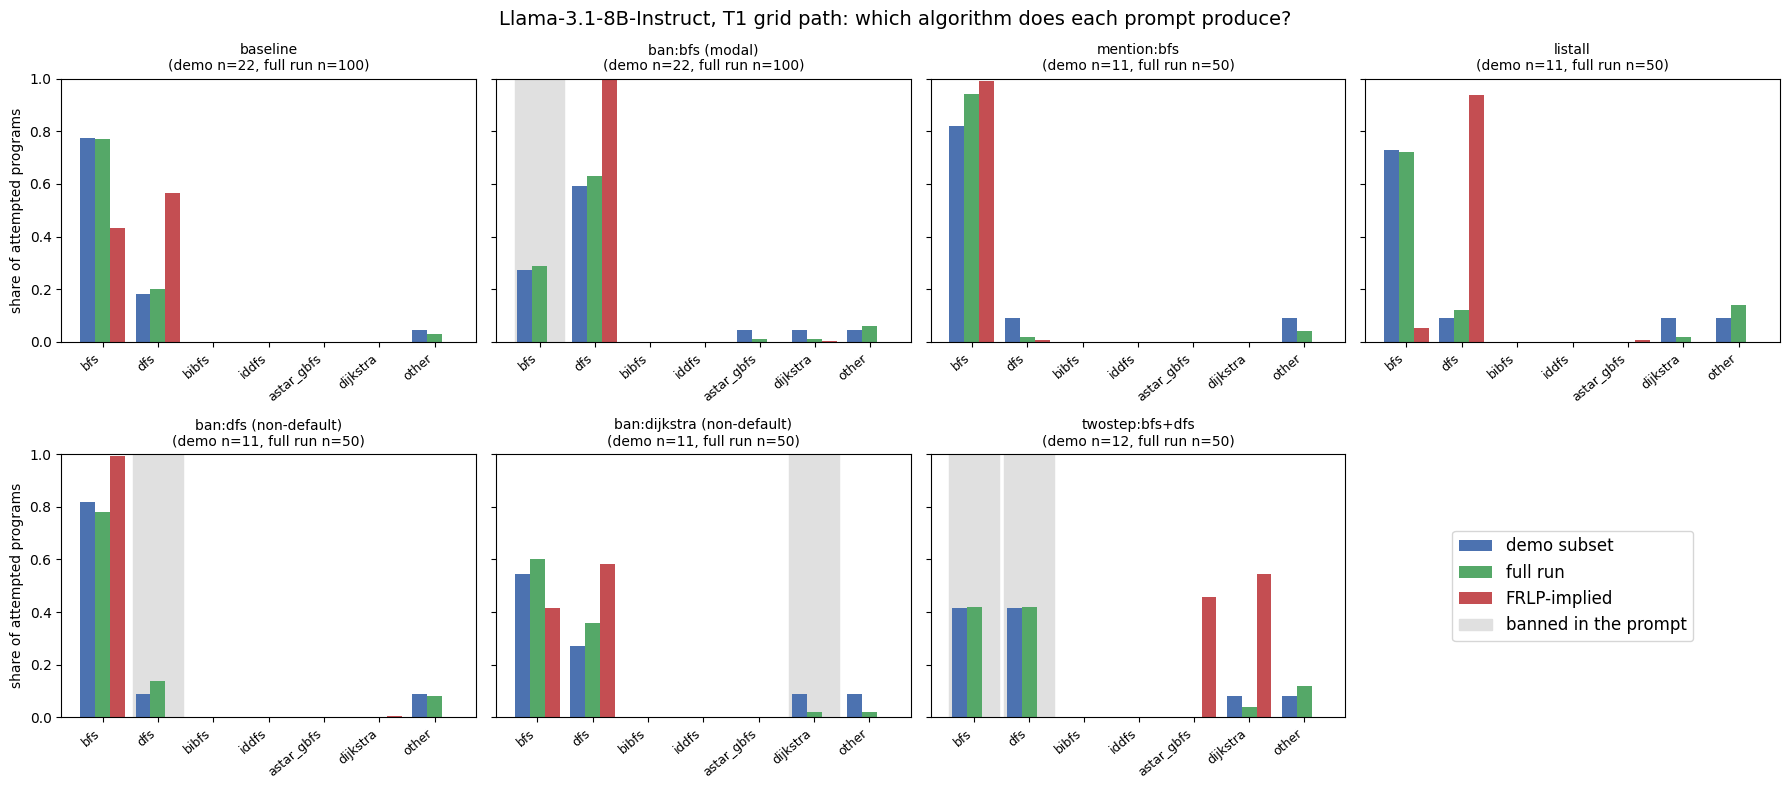

In [18]:
events = {e["name"]: e for e in md["events"]["t1"]}          # the run's 7 T1 events (prompts + full-run counts)
sub_rows = read_jsonl(DATA / "labelled.jsonl")
cats = td.algs + ["other"]
fig, axes = plt.subplots(2, 4, figsize=(18, 8), sharey=True)
for ax, (name, e) in zip(axes.flat, events.items()):
    rs = [r for r in sub_rows if r["condition"] in e["conds"] and r["label"] != "no_code"]
    sub = collections.Counter(r["label"] for r in rs)
    Se = [j for j in td.algs if j not in e["banned"]]
    Lm = np.nanmean([v.a(c, Se) for c in e["conds"]], axis=0)  # template-mean FRLP over the event's prompts
    pm = np.exp(Lm - np.nanmax(Lm))
    frlp = dict(zip(Se, pm / np.nansum(pm)))
    n_att = sum(e["attempted_counts"].values())
    bars = {f"demo subset": [sub.get(c, 0) / max(1, len(rs)) for c in cats],
            "full run": [e["attempted_counts"].get(c, 0) / max(1, n_att) for c in cats],
            "FRLP-implied": [frlp.get(c, 0.0) for c in cats]}
    x = np.arange(len(cats))
    for k, (lab, y) in enumerate(bars.items()):
        ax.bar(x + (k - 1) * 0.27, y, width=0.27, label=lab, color=("#4C72B0", "#55A868", "#C44E52")[k])
    for c in e["banned"]:
        ax.axvspan(cats.index(c) - 0.45, cats.index(c) + 0.45, color="0.88", zorder=0)
    ax.set_title(f"{name}\n(demo n={len(rs)}, full run n={n_att})", fontsize=10)
    ax.set_xticks(x, cats, rotation=40, ha="right", fontsize=9)
    ax.set_ylim(0, 1)
for ax in axes[:, 0]:
    ax.set_ylabel("share of attempted programs")
axes.flat[-1].axis("off")
h, l = axes.flat[0].get_legend_handles_labels()
axes.flat[-1].legend(h + [plt.Rectangle((0, 0), 1, 1, color="0.88")], l + ["banned in the prompt"], loc="center", fontsize=12)
fig.suptitle("Llama-3.1-8B-Instruct, T1 grid path: which algorithm does each prompt produce?", fontsize=14)
fig.tight_layout()
plt.show()

### FRLP geometry: the prompts in algorithm-preference space

Each prompt condition $c$ has a 6-dimensional FRLP vector $(L_{bfs}(c), \dots, L_{dijkstra}(c))$. Subtracting its mean over the algorithms (a centred log-ratio) keeps only the model's *relative* preferences.

- **Left:** the centred FRLP of all 35 sampled T1 prompts, grouped by event.
- **Right:** the same 35 points on their first two principal components, coloured by event. Stars mark the event centroids, and arrows show each algorithm's loading.

A ban moves the prompt away from the banned algorithm's direction. Whether it moves toward one specific substitute or along a common ladder is the question the C1 analysis formalises; in the full run that test was descriptive only, with SHARE 0.80, "not resolved at this N".

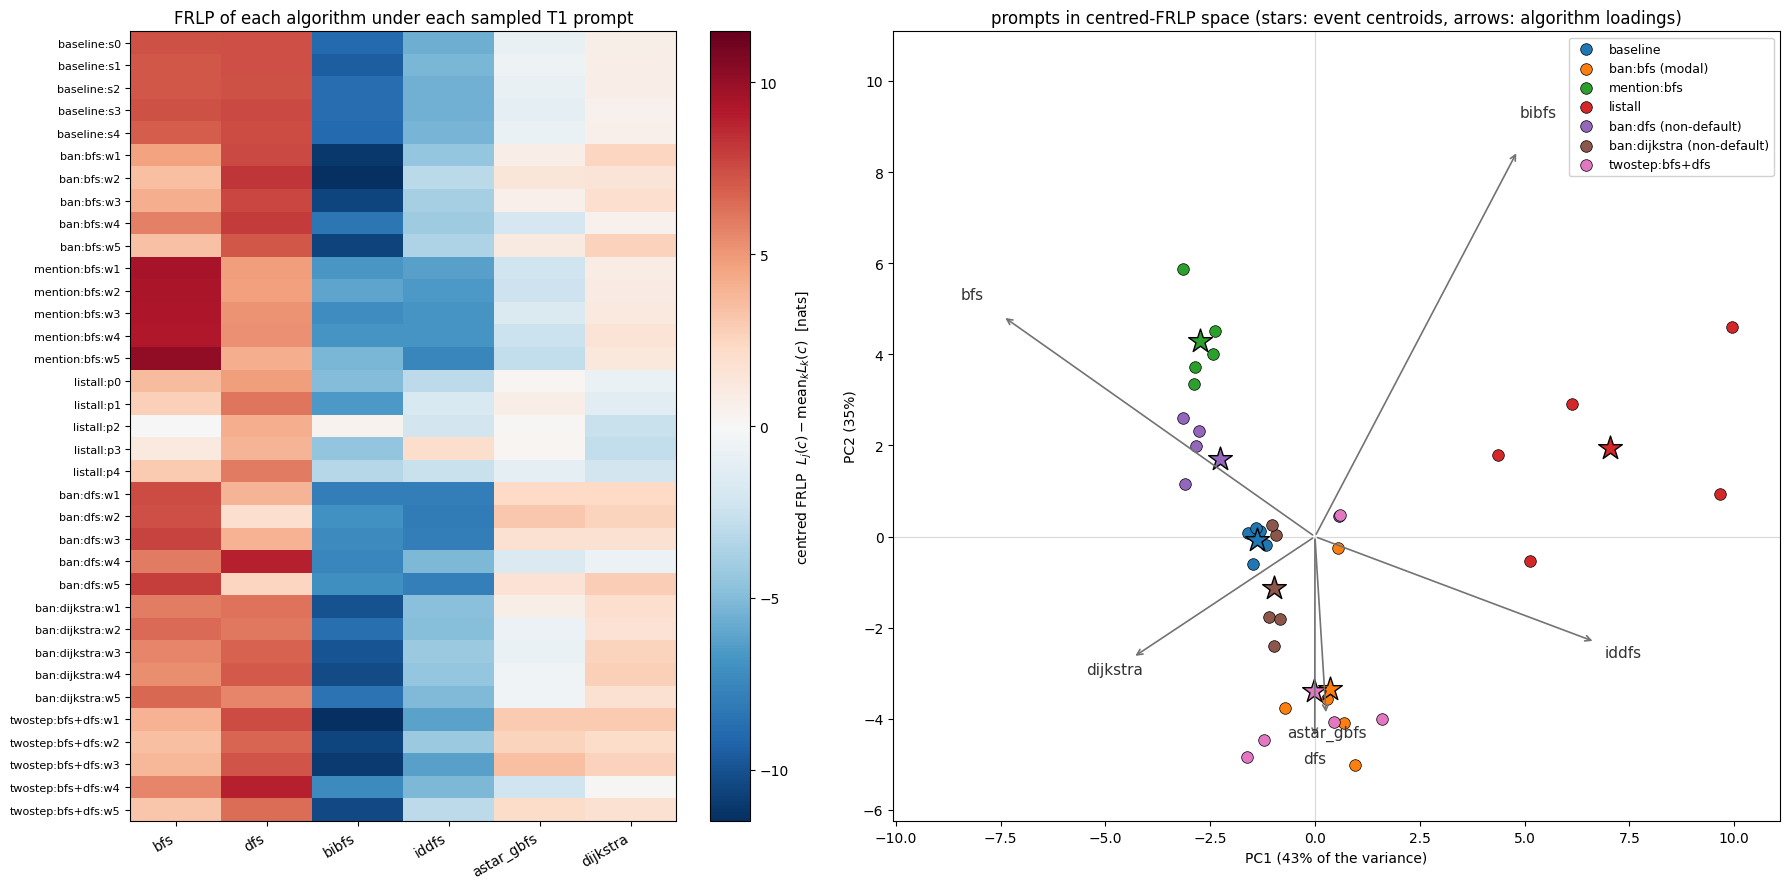

In [19]:
ev_of = {c: name for name, e in events.items() for c in e["conds"]}
names = list(events)
sampled_conds = sorted((c for c in td.conds if c in ev_of), key=lambda c: (names.index(ev_of[c]), c))
Lc = np.array([v.a(c, td.algs) for c in sampled_conds])     # [35, 6] FRLP in nats
Z = Lc - Lc.mean(axis=1, keepdims=True)                      # centred log-ratio per prompt

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 9), gridspec_kw={"width_ratios": [1, 1.3]})
lim = np.nanmax(np.abs(Z))
im = ax1.imshow(Z, aspect="auto", cmap="RdBu_r", vmin=-lim, vmax=lim)
ax1.set_xticks(range(len(td.algs)), td.algs, rotation=30, ha="right")
ax1.set_yticks(range(len(sampled_conds)), sampled_conds, fontsize=8)
fig.colorbar(im, ax=ax1, label="centred FRLP  $L_j(c) - \\mathrm{mean}_k L_k(c)$  [nats]")
ax1.set_title("FRLP of each algorithm under each sampled T1 prompt")

Zc = Z - Z.mean(axis=0, keepdims=True)                       # PCA of the 35 prompts (SVD of the centred matrix)
U, S, Vt = np.linalg.svd(Zc, full_matrices=False)
P = Zc @ Vt[:2].T
expl = S ** 2 / np.sum(S ** 2)
colors = plt.cm.tab10(np.arange(len(names)))
for k, name in enumerate(names):
    idx = [i for i, c in enumerate(sampled_conds) if ev_of[c] == name]
    ax2.scatter(P[idx, 0], P[idx, 1], s=70, color=colors[k], edgecolor="k", linewidth=0.5, label=name)
    ax2.scatter(*P[idx].mean(axis=0), s=320, marker="*", color=colors[k], edgecolor="k")
scale = 0.85 * np.abs(P).max() / np.abs(Vt[:2]).max()
tips = Vt[:2].T * scale                                       # algorithm loadings, in PC units
for j, a in enumerate(td.algs):
    ax2.annotate("", xy=tuple(tips[j]), xytext=(0, 0), arrowprops=dict(arrowstyle="->", color="0.45", lw=1.2))
    ax2.text(*(tips[j] * 1.1), a, color="0.2", fontsize=11, ha="center", va="center")
ext = np.vstack([P, tips * 1.2])                              # axis limits cover the points and the arrow labels
pad = 0.06 * (ext.max(axis=0) - ext.min(axis=0))
ax2.set_xlim(ext[:, 0].min() - pad[0], ext[:, 0].max() + pad[0])
ax2.set_ylim(ext[:, 1].min() - pad[1], ext[:, 1].max() + pad[1])
ax2.axhline(0, color="0.85", lw=0.8, zorder=0)
ax2.axvline(0, color="0.85", lw=0.8, zorder=0)
ax2.set_xlabel(f"PC1 ({expl[0]:.0%} of the variance)")
ax2.set_ylabel(f"PC2 ({expl[1]:.0%})")
ax2.set_title("prompts in centred-FRLP space (stars: event centroids, arrows: algorithm loadings)")
ax2.legend(fontsize=9, loc="best", framealpha=0.9)
fig.tight_layout()
plt.show()

## What to take away, and the rest of `method.py`

**Reading the results.** The numbers below are from the full run on T1. The demo subset reproduces each of its predictions exactly, and its accuracies come out within a few points: overall FRLP 0.51, sampled ladder 0.76, latent ladder 0.39 and association 0.43, against 0.56, 0.79, 0.40 and 0.43 in the full run.
- **Single bans of the two common algorithms are easy.** Banning BFS sends Llama to DFS, and banning DFS sends it back to BFS. All four predictors get these right (0.89–0.91).
- **FRLP's weak spot is calibration at baseline.** It ranks DFS above BFS on unbanned prompts, so on baseline and list-all prompts it predicts DFS while Llama writes BFS (accuracy 0.20 and 0.12). The empirical sampled ladder wins overall on T1: 0.79 against 0.56.
- **FRLP helps where the prompt matters.** Under *mention BFS*, it follows the mention prime to BFS (0.94), while the prompt-blind latent ladder stays on DFS (0.02). Under *ban Dijkstra*, FRLP scores 0.67 against the latent ladder's 0.37.

**The other stages.** `outputs` is the last of `method.py`'s stages. The others are thin dispatchers to repository modules, and each needs something this notebook does not have: a GPU for vLLM generation or for HF scoring of the 8B model, the OpenRouter judge, or the full data. Here is the dispatcher, unchanged:

```python
def run(mod: str, *args: str) -> int:
    cmd = [PY, "-W", "ignore", "-m", mod, *args]
    logger.info(f"$ {' '.join(cmd)}")
    return subprocess.call(cmd, cwd=ROOT)

@logger.catch(reraise=True)
def main() -> None:
    ap = argparse.ArgumentParser(description=__doc__, formatter_class=argparse.RawDescriptionHelpFormatter)
    ap.add_argument("stage")
    ap.add_argument("arg", nargs="?")
    a = ap.parse_args()
    setup_logging("method")
    s = a.stage
    if s == "setup":
        subprocess.call(["sha256sum", "-c", "--quiet", "SHA256SUMS"], cwd=ROOT / "canon")
        subprocess.call([sys.executable, "-I", "scripts/extract_dependency.py"], cwd=ROOT)
        run("src.commit", "setup-only", "results/frozen_config.json") if False else None
    elif s == "recheck":
        run("src.label_worker", "recheck")
    elif s == "gen":
        run("src.gen_client", "--phase", a.arg)
    elif s == "label":
        run("src.label_worker", "label", *(["--phases", a.arg] if a.arg else []))
    elif s == "audit":
        run("src.label_worker", "audit")
        run("src.label_worker", "audit2")
    elif s == "forced":
        run("src.forced_set")
    elif s == "score":
        run("src.score_session", "--phase", a.arg)
    elif s == "commit":
        run("src.commit", a.arg or "freeze: S0.9 before the first S5 score")
    elif s == "test9":
        run("src.test_analysis_c1")
    elif s == "analyse":
        run("src.run_analysis")
    elif s == "figures":
        run("src.figures")
    elif s == "rederive":
        subprocess.call([PY, "audit/rederive.py"], cwd=ROOT)
    elif s == "outputs":
        outputs()
    else:
        raise SystemExit(f"unknown stage {s}")
```

| stage | what it does | needs |
|---|---|---|
| `setup` | verifies the `canon/` copy (SHA256SUMS), extracts the 718-noun bank, writes the frozen config | CPU |
| `recheck`, `label`, `audit` | canonical labeller re-check (22/22), mechanism labels (judge only on disagreement), Llama label audit | CPU + OpenRouter |
| `gen A1..A6, C` | 1,780 seeded generations: baselines, bans, mention twins, list-all, two-step bans, forced programs, free-form answers | vLLM + GPU |
| `forced` | forced set: name scrub, validation, halves, coverage | CPU |
| `score B, D` | 39,768 HF program scores (prefill once, KV reuse, fp32 head) | 24 GB GPU |
| `commit` | hash-chained sha256 commitments (freeze before the first S5 score) | CPU |
| `analyse`, `figures`, `rederive` | S6: FRLP gate, C1 with bootstrap and exact AIM nulls, route test, figures, independent re-derivation | CPU |
| **`outputs`** | **this notebook** | CPU |

To reproduce the full run, see the artifact's `reproducibility.md`:
- **CPU-only re-analysis:** run `./restore.sh`, then `python -m src.run_analysis`, `audit/rederive.py`, `-m src.figures` and `method.py outputs`.
- **Full regeneration:** needs a GPU with 20 GB or more, `scripts/serve_vllm.sh`, and the stage order given there.